In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt

scopepath = '/Users/sergivela/Documents/SCOPE/Program/'
sys.path.append(scopepath)

from Scope import *

In [2]:
sys_path = "/Users/sergivela/Documents/SCOPE/Database_SCO/test_TZVP/tests_TZVP.npy"
figures_path = "/Users/sergivela/Documents/SCOPE/Database_SCO/test_TZVP/"

In [3]:
systems = load_binary(sys_path)

## Further Curates The list

In [4]:
curated_systems = []
for sys in systems:
    keep = True
    for j in list(["b3lyp_opt", "b3lyp_freq","tzvp_opt", "tzvp_freq"]):
        found, job_HS = sys.branches[0].recipes[0].find_job(j)
        if not job_HS.isfinished: keep = False
        found, job_LS = sys.branches[0].recipes[1].find_job(j)
        if not job_LS.isfinished: keep = False
    if keep: curated_systems.append(sys); print(sys.refcode)

ACAHUJ02
ADAQUU
ADEJOK
AFANEB02
AFOYUS02
AFUHOB01
AGIZEX
AKEMUY
AKENAF
AMIHUA
APINUJ
AROZIS
ATASEU
ATAXAW
ATAXEB
ATOZUG03
ATUBIC
AWUKEK01
AXAKIT01
RAKZIM


## Compares Energies

In [5]:
svp, tzvp = [], []

for sys in curated_systems:
    found1, hs1 = find_state(sys.HS_ref_mol,"b3lyp_opt")
    found2, hs2 = find_state(sys.HS_ref_mol,"tzvp_opt")
    found3, ls1 = find_state(sys.LS_ref_mol,"b3lyp_opt")
    found4, ls2 = find_state(sys.LS_ref_mol,"tzvp_opt")

    en_hs1 = hs1.results["energy"].value
    en_hs2 = hs2.results["energy"].value
    en_ls1 = ls1.results["energy"].value
    en_ls2 = ls2.results["energy"].value

    svp.append((en_hs1-en_ls1)*Constants.har2kJmol)
    tzvp.append((en_hs2-en_ls2)*Constants.har2kJmol)
    #print(sys.refcode, np.round((en_hs1-en_ls1)*Constants.har2kJmol,4), np.round((en_hs2-en_ls2)*Constants.har2kJmol,4))


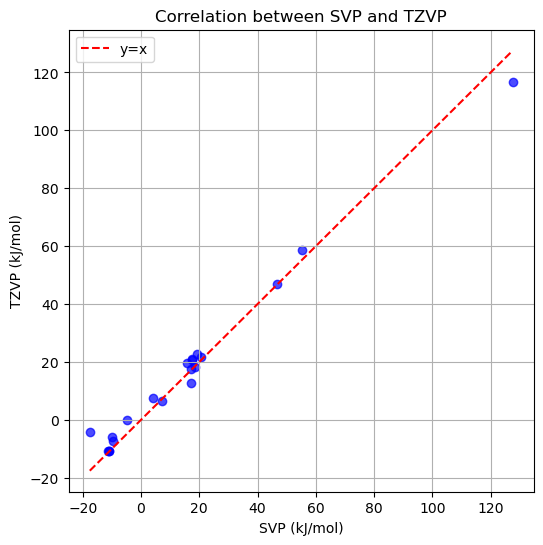

In [6]:
plt.figure(figsize=(6,6))
plt.scatter(svp, tzvp, color='blue', alpha=0.7)
plt.xlabel('SVP (kJ/mol)')
plt.ylabel('TZVP (kJ/mol)')
plt.title('Correlation between SVP and TZVP')
plt.plot([min(svp), max(svp)], [min(svp), max(svp)], 'r--', label='y=x')
plt.legend()
plt.grid(True)
plt.show()

In [7]:
# Calculate the Pearson correlation coefficient between svp and tzvp
correlation = np.corrcoef(svp, tzvp)[0, 1]
print(f"Pearson correlation coefficient between SVP and TZVP: {correlation:.4f}")

Pearson correlation coefficient between SVP and TZVP: 0.9934


In [8]:
# Calculate R^2 (coefficient of determination) between svp and tzvp
r_squared = correlation ** 2
print(f"R^2 between SVP and TZVP: {r_squared:.4f}")

R^2 between SVP and TZVP: 0.9869


## Time Comparison

In [ ]:
sys = curated_systems[0]
found, job_HS = sys.branches[0].recipes[0].find_job(j)

FileNotFoundError: [Errno 2] No such file or directory: '/home/svela/SCOPE/Database_SCO/5-Complexes_Iso/ACAHUJ02/Isolated/ACAHUJ02_opt2_r1_HS.log'

In [ ]:
times1, times2 = [], []

for sys in curated_systems:
    time1 = 0
    time2 = 0
    blocks1 = 0
    blocks2 = 0

    for j in list(["b3lyp_opt", "b3lyp_freq"]):
        found, job_HS = sys.branches[0].recipes[0].find_job(j)
        for comp in job_HS.computations:
            if not hasattr(comp,"cpu_time"): print(comp)
            time1 += comp.cpu_time
            if hasattr(comp,"output"): blocks1 += len(comp.output.get_opt_blocks())
        found, job_LS = sys.branches[0].recipes[1].find_job(j)
        for comp in job_LS.computations:
            if not hasattr(comp,"cpu_time"): print(comp)
            time1 += comp.cpu_time
            blocks1 += len(comp.output.get_opt_blocks())
    times1.append(time1)
    allblocks1.append(blocks2)

    for j in list(["tzvp_opt", "tzvp_freq"]):
        found, job_HS = sys.branches[0].recipes[0].find_job(j)
        for comp in job_HS.computations:
            if not hasattr(comp,"cpu_time"): reg_general(comp); print(comp)
            time2 += comp.cpu_time
            blocks2 += len(comp.output.get_opt_blocks())
        found, job_LS = sys.branches[0].recipes[1].find_job(j)
        for comp in job_LS.computations:
            if not hasattr(comp,"cpu_time"): print(comp)
            time2 += comp.cpu_time    
            blocks2 += len(comp.output.get_opt_blocks())
    times2.append(time2)
    allblocks2.append(blocks2)

AttributeError: 'computation' object has no attribute 'output'

In [11]:
## Convert to Hours
times1 = np.array(times1)/3600 
times2 = np.array(times2)/3600

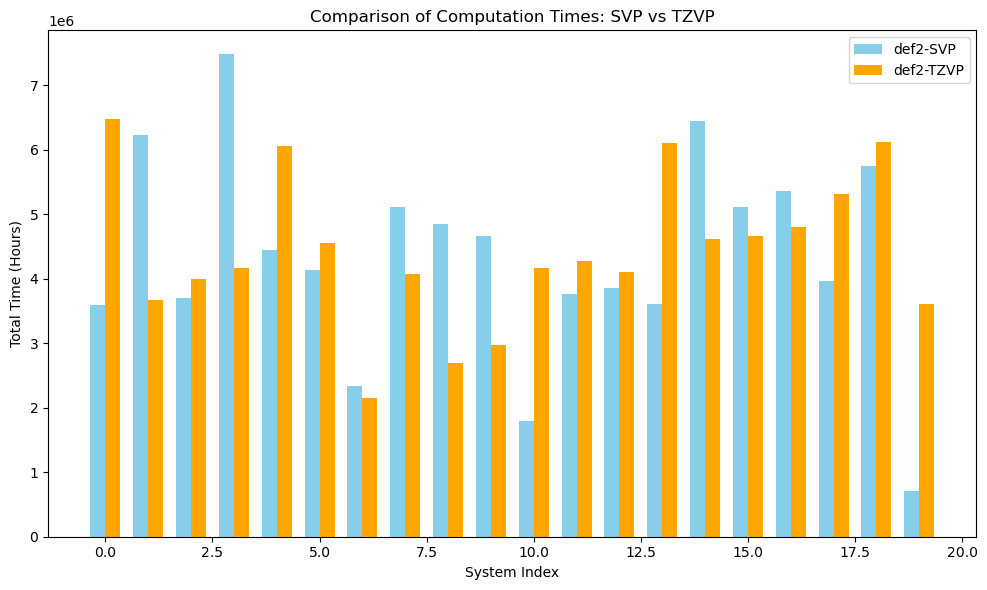

In [10]:
# Bar plot comparing times1 and times2
indices = np.arange(len(times1))
width = 0.35

plt.figure(figsize=(10,6))
plt.bar(indices - width/2, times1, width, label='def2-SVP', color='skyblue')
plt.bar(indices + width/2, times2, width, label='def2-TZVP', color='orange')
plt.xlabel('System Index')
plt.ylabel('Total Time (Hours)')
plt.title('Comparison of Computation Times: SVP vs TZVP')
plt.legend()
plt.tight_layout()
plt.show()

In [48]:
times1[0]

324003.2